# Forward and Inverse Kinematics

**Kinematics** describes the motion of a robotic system without considering the forces or torques responsible for that motion.

In robotics, kinematics allows us to determine the position and orientation of different parts of a robot, particularly its **end effector**.

There are two fundamental problems in robot kinematics:

### Forward Kinematics

In **forward kinematics**, the robot configuration (joint positions) is known,
and we calculate the **position of the end effector**.

Mathematically, forward kinematics can be expressed as:

$$
\boldsymbol{q}
\longrightarrow
\boldsymbol{p}^{W}_{E}
$$

where:

- $\boldsymbol{q}$ is the robot configuration vector representing joint positions.
- $\boldsymbol{p}^{W}_{E}$ is the position of the end effector expressed in the world frame.

Forward kinematics can also determine the **orientation** of the end effector.
The complete end-effector pose can be represented using a
**homogeneous transformation matrix**:

$$
\boldsymbol{q}
\longrightarrow
\boldsymbol{H}^{W}_{E}
$$

where $\boldsymbol{H}^{W}_{E}$ describes the position and orientation
of the end-effector frame relative to the world frame.

For example, if we know the joint angles of a robotic manipulator,
we can calculate where its end effector is located and how it is oriented.

### Inverse Kinematics

In **inverse kinematics**, we start with an end-effector position or pose and determine the robot configuration.

$$
\boldsymbol{p}^{W}_{E}
\longrightarrow
\boldsymbol{q}
$$

where $\boldsymbol{p}^{W}_{E}$ is the end-effector position expressed in the world frame.

In [31]:
# Included Packages and Functions
import numpy as np
import matplotlib.pyplot as plt

---
## Helper Functions from Lecture 3

In Lecture 3, you developed functions to construct rotation matrices and homogeneous transformation matrices (HTMs).

These functions will be reused throughout this notebook.

Recall that a homogeneous transformation matrix is defined as

$$
\boldsymbol{H}^{A}_{B}
=
\begin{bmatrix}
\boldsymbol{R}^{A}_{B} & \boldsymbol{p}^{A}_{B}\\
\boldsymbol{0}_{1\times3} & 1
\end{bmatrix}.
$$

The matrix combines:

- $\boldsymbol{R}^{A}_{B}$: the orientation of frame $\mathcal{F}_B$ relative to frame $\mathcal{F}_A$,
- $\boldsymbol{p}^{A}_{B}$: the position of the origin of frame $\mathcal{F}_B$, expressed in frame $\mathcal{F}_A$.

When several coordinate frames are connected, the transformations can be multiplied:

$$
\boldsymbol{H}^{A}_{C}
=
\boldsymbol{H}^{A}_{B}
\boldsymbol{H}^{B}_{C}
$$

**Remember:** The order of matrix multiplication is important.


**Angle convention:** The rotation functions `Rx()`, `Ry()` and `Rz()` accept angles in degrees.

In [32]:
# Helper Functions from Lecture 3

def Rx(alpha):
    """
    Construct a rotation matrix about the x-axis.

    Input:
        alpha : rotation angle in degrees

    Output:
        3x3 rotation matrix
    """

    # Convert degrees to radians
    a = np.radians(alpha)

    ca = np.cos(a)
    sa = np.sin(a)

    return np.array([
        [1,  0,   0],
        [0, ca, -sa],
        [0, sa,  ca]
    ])


def Ry(alpha):
    """
    Construct a rotation matrix about the y-axis.

    Input:
        alpha : rotation angle in degrees

    Output:
        3x3 rotation matrix
    """

    a = np.radians(alpha)

    ca = np.cos(a)
    sa = np.sin(a)

    return np.array([
        [ ca, 0, sa],
        [  0, 1,  0],
        [-sa, 0, ca]
    ])


def Rz(alpha):
    """
    Construct a rotation matrix about the z-axis.

    Input:
        alpha : rotation angle in degrees

    Output:
        3x3 rotation matrix
    """

    a = np.radians(alpha)

    ca = np.cos(a)
    sa = np.sin(a)

    return np.array([
        [ca, -sa, 0],
        [sa,  ca, 0],
        [ 0,   0, 1]
    ])


def ht(r, t):
    """
    Construct a 4x4 Homogeneous Transformation Matrix.

    Inputs:
        r : 3x3 rotation matrix
        t : translation vector with 3 components

    Output:
        4x4 homogeneous transformation matrix
    """

    # Check the dimensions
    if r.shape != (3, 3):
        raise ValueError("Rotation matrix must be 3x3")

    if t.size != 3:
        raise ValueError("Translation vector must have 3 components")

    # Start with a 4x4 identity matrix
    H = np.eye(4)

    # Insert the rotation matrix
    H[:3, :3] = r

    # Insert the translation vector
    H[:3, 3] = t

    return H

---
---
## ✏️ Task 1.0 - Forward Kinematics of an Underwater Vehicle-Manipulator System

Consider the underwater vehicle-manipulator system (UVMS) shown in Figure 1.

<figure>
    <img src="graphics/task_1.png" width="800">
    <figcaption><b>Figure 1:</b> Underwater vehicle-manipulator system (UVMS).</figcaption>
</figure>

The system consists of an underwater vehicle carrying a two-degree-of-freedom (2-DOF) robotic manipulator with two revolute joints.

The objective is to determine the **position and orientation of the end effector relative to the world frame**.

### Robot Configuration

The complete configuration of the UVMS is described by

$$
\boldsymbol{q}
=
\begin{bmatrix}
x &
y &
z &
\psi_B &
q_1 &
q_2
\end{bmatrix}^{T}
$$

where:

- $x$, $y$ and $z$ describe the position of the vehicle in the world frame.
- $\psi_B$ is the vehicle rotation about the world $z$-axis.
- $q_1$ is the first manipulator joint angle.
- $q_2$ is the second manipulator joint angle.


### Manipulator

The manipulator is attached to the vehicle at a fixed position

$$
\boldsymbol{p}^{B}_{1}
=
\begin{bmatrix}
-0.05\\
0.30\\
-0.15
\end{bmatrix}
\text{ m}.
$$

The mounting frame $\mathcal{F}_1$ also has a fixed orientation relative to the vehicle frame.

Starting with the frames aligned, the mounting undergoes the following rotations:

1. $15^\circ$ about the **current $z$-axis**.
2. $-20^\circ$ about the **current $y$-axis**.
3. $30^\circ$ about the **current $x$-axis**.


The manipulator consists of two links with lengths

$$
L_1=0.60\text{ m},
\qquad
L_2=0.40\text{ m}.
$$

Both joints rotate about their local $z$-axes.

The manipulator moves in its local $x$-$y$ plane.

The coordinate frames are:

- $\mathcal{F}_W$: world-fixed frame.
- $\mathcal{F}_B$: vehicle body-fixed frame.
- $\mathcal{F}_1$: first manipulator joint frame.
- $\mathcal{F}_2$: second manipulator joint frame.
- $\mathcal{F}_E$: end-effector frame.

The forward kinematics problem is to calculate the pose of the end-effector in respect to the world frame.


---
### Task 1.1

Before implementing the forward kinematics, we must identify how the coordinate frames are connected.

Using Figure 1, determine the sequence of transformations required to express the end-effector frame $\mathcal{F}_E$ relative to the world frame $\mathcal{F}_W$.

Write the complete transformation chain for

$$
\boldsymbol{H}^{W}_{E}.
$$

Hint: Follow the frames from $\mathcal{F}_W$ to $\mathcal{F}_E$.

#### Your Answer

$$
\boldsymbol{H}^{W}_{E}
= \boldsymbol{H}^{W}_{B}\boldsymbol{H}^{B}_{1}\boldsymbol{H}^{1}_{2}\boldsymbol{H}^{2}_{E}
$$

---
### Task 1.2 - Implementing the Forward Kinematics

Using Figure 1 and the information provided in Task 1.0, complete the function below to calculate the end-effector pose.

The function is provided with the configuration vector of the UVMS

$$
\boldsymbol{q}
=
\begin{bmatrix}
x &
y &
z &
\psi_B &
q_1 &
q_2
\end{bmatrix}^{T}
$$

and returns

$$
\boldsymbol{H}^{W}_{E}.
$$

Use `Rz()` and `ht()` to complete the function


In [33]:
# Task 1.2 - UVMS Forward Kinematics

# Manipulator link lengths (m)
L1 = 0.60
L2 = 0.40


# Fixed mounting position in the vehicle frame
p_B1 = np.array([-0.05, 0.30, -0.15])

# Fixed mounting orientation
# Successive rotations about the current frame:
# 1. Rotate about the current z-axis by angle_z
# 2. Rotate about the updated y-axis by angle_y
# 3. Rotate about the updated x-axis by angle_x
R_B1 = Rz(15) @ Ry(-20) @ Rx(30)

# Mounting homogeneous transformation
H_B1 = ht(R_B1, p_B1)


def uvms_forward_kinematics(q):
    """
    Calculate the end-effector pose relative to the world frame.

    Input:
        q : robot configuration
            [x, y, z, psi_B, q1, q2]

            Positions are in metres.
            Angles are in degrees.

    Output:
        H_WE : 4x4 homogeneous transformation matrix
    """

    # Extract the configuration variables
    x, y, z, psi_B, q1, q2 = q

    # Vehicle orientation relative to the world frame
    R_WB = Rz(psi_B)

    # Vehicle position in the world frame
    p_WB = np.array([x, y, z])

    # Vehicle pose relative to the world frame
    H_WB = ht(R_WB, p_WB)

    # Transformation from Frame 1 to Frame 2
    # First joint rotation and first link translation
    H_12 = ht(
        Rz(q1),
        np.array([
            L1 * np.cos(np.radians(q1)),
            L1 * np.sin(np.radians(q1)),
            0.0
        ])
    )

    # Transformation from Frame 2 to the end effector
    # Second joint rotation and second link translation
    H_2E = ht(
        Rz(q2),
        np.array([
            L2 * np.cos(np.radians(q2)),
            L2 * np.sin(np.radians(q2)),
            0.0
        ])
    )

    # Combine the transformations
    H_WE = H_WB @ H_B1 @ H_12 @ H_2E

    return H_WE

---
### Task 1.3

Evaluate your forward kinematic model for

$$
\boldsymbol{q}
=
\begin{bmatrix}
2.0 &
1.0 &
-1.5 &
30^\circ &
20^\circ &
-40^\circ
\end{bmatrix}^{T}.
$$

Calculate

$$
\boldsymbol{H}^{W}_{E}
$$

and extract the end-effector orientation and position,

$$
\boldsymbol{R}^{W}_{E},
\qquad
{}^{W}\boldsymbol{p}_{E}.
$$

In [34]:
# Task 1.3

# Define the robot configuration
# q = [x, y, z, psi_B, q1, q2]
# Positions in metres, angles in degrees
q = np.array([
    2.0,
    1.0,
    -1.5,
    30,
    20,
    -40
])

# Calculate the end-effector pose
H_WE = uvms_forward_kinematics(q)

# Extract the end-effector position
p_WE = H_WE[:3, 3]

# Extract the end-effector orientation
R_WE = H_WE[:3, :3]

print("End-effector orientation:")
print(R_WE)

print("\nEnd-effector position:")
print(p_WE)

End-effector orientation:
[[ 0.8751926  -0.46181199  0.14410968]
 [ 0.45630518  0.68907173 -0.5629971 ]
 [ 0.1606969   0.55848889  0.81379768]]

End-effector position:
[ 2.38092941  1.89281579 -1.29646681]


---
### Task 1.4 - Stretch

In Task 1.3, you calculated the end-effector position for one robot configuration.

The forward kinematic model can also be used to investigate how the end-effector position changes as the robot moves.

In this task, you will evaluate the model for several configurations and visualise the resulting end-effector positions in three-dimensional space.

The configuration vector is

$$
\boldsymbol{q}
=
\begin{bmatrix}
x &
y &
z &
\psi_B &
q_1 &
q_2
\end{bmatrix}^{T}.
$$

Complete the code below to:

1. Calculate the end-effector pose for each of the eight provided robot configurations.
2. Extract and store the end-effector positions.
3. Plot the positions in 3D.

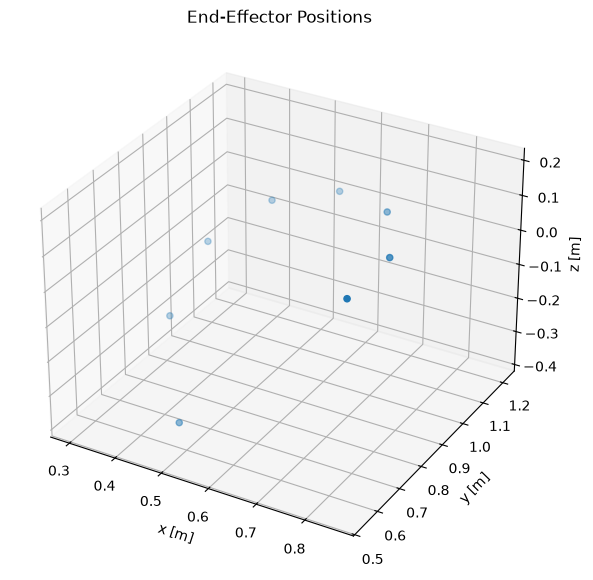

In [35]:
# Task 1.4

# Define eight robot configurations
# q = [x, y, z, psi_B, q1, q2]
# Positions in metres, angles in degrees
configurations = np.array([
    [0.0, 0.0,  0.0,   0.0,  0.0,   0.0],
    [0.2, 0.0, -0.1,  15.0, 10.0, -10.0],
    [0.4, 0.1, -0.2,  30.0, 20.0, -20.0],
    [0.6, 0.2, -0.3,  45.0, 30.0, -30.0],
    [0.8, 0.3, -0.4,  60.0, 40.0, -40.0],
    [1.0, 0.4, -0.5,  75.0, 50.0, -50.0],
    [1.2, 0.5, -0.6,  90.0, 60.0, -60.0],
    [1.4, 0.6, -0.7, 105.0, 70.0, -70.0]
])


# Create a list to store the end-effector positions
ee_positions = []


# Evaluate the forward kinematics for each configuration
for q in configurations:

    # Calculate the end-effector pose
    H_WE = uvms_forward_kinematics(q)

    # Extract the end-effector position from the HTM
    p_WE = H_WE[:3, 3]

    # Store the position
    ee_positions.append(p_WE)


# Convert the list of positions to a NumPy array
ee_positions = np.array(ee_positions)

# Handle incomplete student answers
if ee_positions.ndim != 2 or ee_positions.shape[1] != 3:
    ee_positions = np.empty((0, 3))


# Create a 3D plot
fig = plt.figure(figsize=(8, 7))


# Create a 3D axis
ax = fig.add_subplot(111, projection='3d')


# Plot the end-effector positions
ax.scatter(
    ee_positions[:, 0],
    ee_positions[:, 1],
    ee_positions[:, 2]
)


# Label the axes
ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")
ax.set_zlabel("z [m]")

ax.set_title("End-Effector Positions")

plt.show()

---
---
## ✏️ Task 2.0 - Changing the End Effector

In Task 1, you developed a forward kinematic model to calculate the pose of the manipulator's end-effector frame.

The result was the homogeneous transformation

$$
\boldsymbol{H}^{W}_{E}.
$$

In practice, underwater manipulators can be equipped with different tools, such as cameras, sampling probes and sonar sensors.

Each tool has its own position and orientation relative to the end-effector frame.

Rather than developing a new forward kinematic model for every tool, we can use the existing model and introduce an additional transformation.

For a tool frame $\mathcal{F}_T$ attached to the end effector,

$$
\boldsymbol{H}^{W}_{T}
=
\boldsymbol{H}^{W}_{E}
\boldsymbol{H}^{E}_{T}
$$

where:

- $\boldsymbol{H}^{W}_{E}$ describes the end-effector pose in the world frame.
- $\boldsymbol{H}^{E}_{T}$ describes the tool pose relative to the end effector.
- $\boldsymbol{H}^{W}_{T}$ describes the tool pose in the world frame.

Consider the following three tools.

### Option A - Inspection Camera

The inspection camera is positioned at

$$
\boldsymbol{p}^{E}_{C}
=
\begin{bmatrix}
0.15\\
0\\
0
\end{bmatrix}
\text{ m}.
$$

The camera has the same orientation as the end-effector frame.


### Option B - Sampling Probe

The sampling probe is positioned at

$$
\boldsymbol{p}^{E}_{P}
=
\begin{bmatrix}
0.25\\
0\\
0
\end{bmatrix}
\text{ m}.
$$


### Option C - Sonar Sensor

The sonar sensor is positioned at

$$
\boldsymbol{p}^{E}_{S}
=
\begin{bmatrix}
0.10\\
0\\
0.05
\end{bmatrix}
\text{ m}.
$$

Unlike the camera and probe, the sonar sensor is rotated by $45^\circ$ about the $y$-axis of the end-effector frame.

In the following task, you will determine the pose of each tool relative to the world frame.

---
### Task 2.1

Using the tool positions and orientations provided in Task 2.0, construct the following homogeneous transformations:

$$
\boldsymbol{H}^{E}_{C},
\qquad
\boldsymbol{H}^{E}_{P},
\qquad
\boldsymbol{H}^{E}_{S}.
$$

These describe the three introduced tool poses relative to the end-effector frame.

Then use the forward kinematics from Task 1 to calculate

$$
\boldsymbol{H}^{W}_{C},
\qquad
\boldsymbol{H}^{W}_{P},
\qquad
\boldsymbol{H}^{W}_{S}.
$$

Use the same robot configuration as Task 1.3.


In [36]:
# Task 2.1

# Use the robot configuration from Task 1.3
q = np.array([
    2.0,
    1.0,
    -1.5,
    30,
    20,
    -40
])

H_WE = uvms_forward_kinematics(q)

# Camera

H_EC = ht(
    np.eye(3),
    np.array([0.15, 0.0, 0.0])
)

# Probe

H_EP = ht(
    np.eye(3),
    np.array([0.25, 0.0, 0.0])
)

# Sonar

H_ES = ht(
    Ry(45),
    np.array([0.10, 0.0, 0.05])
)

#Tool Transformations

H_WC = H_WE @ H_EC
H_WP = H_WE @ H_EP
H_WS = H_WE @ H_ES


# Display the results
print("Camera pose:")
print(H_WC)

print("\nProbe pose:")
print(H_WP)

print("\nSonar pose:")
print(H_WS)



Camera pose:
[[ 0.8751926  -0.46181199  0.14410968  2.5122083 ]
 [ 0.45630518  0.68907173 -0.5629971   1.96126156]
 [ 0.1606969   0.55848889  0.81379768 -1.27236228]
 [ 0.          0.          0.          1.        ]]

Probe pose:
[[ 0.8751926  -0.46181199  0.14410968  2.59972756]
 [ 0.45630518  0.68907173 -0.5629971   2.00689208]
 [ 0.1606969   0.55848889  0.81379768 -1.25629259]
 [ 0.          0.          0.          1.        ]]

Sonar pose:
[[ 0.51695369 -0.46181199  0.72075556  2.47565415]
 [ 0.72075556  0.68907173 -0.07544258  1.91029645]
 [-0.46181199  0.55848889  0.68907173 -1.23970724]
 [ 0.          0.          0.          1.        ]]


### Task 2.2

Consider the following desired end-effector positions expressed in the first manipulator frame $\mathcal{F}_1$:

$$
\boldsymbol{p}^{1}_{A}
=
\begin{bmatrix}
0.70\\
-0.20\\
0
\end{bmatrix}
\text{ m},
\qquad
\boldsymbol{p}^{1}_{B}
=
\begin{bmatrix}
0.30\\
-0.20\\
0
\end{bmatrix}
\text{ m},
$$

$$
\boldsymbol{p}^{1}_{C}
=
\begin{bmatrix}
1.10\\
0\\
0
\end{bmatrix}
\text{ m},
\qquad
\boldsymbol{p}^{1}_{D}
=
\begin{bmatrix}
0.10\\
0\\
0
\end{bmatrix}
\text{ m}.
$$

Since the manipulator moves in its local $x$-$y$ plane, the distance to a target is

$$
r=\sqrt{x^2+y^2}.
$$

For this task, assume that:

- The underwater vehicle remains stationary at the world frame origin.
- The vehicle heading is $\psi_B=0^\circ$.
- No additional tool is attached.
- Only the two manipulator joints are allowed to move.

For each target:

1. Calculate the distance of the end-effector from the manipulator base $\mathcal{F}_1$.
2. Determine the minimum and maximum reach of the manipulator.
3. Check whether the target lies within the reachable workspace.
4. Display the target distance and reachability result.


In [37]:
# Task 2.2

# Define the target positions in Frame 1
targets = {
    "A": np.array([0.70, -0.20, 0.00]),
    "B": np.array([0.30, -0.20, 0.00]),
    "C": np.array([1.10,  0.00, 0.00]),
    "D": np.array([0.10,  0.00, 0.00])
}


# Calculate the minimum and maximum reach
r_min = abs(L1 - L2)
r_max = L1 + L2

print("Minimum reach:", r_min, "m")
print("Maximum reach:", r_max, "m")

for name, target in targets.items():

    # Extract the target coordinates
    if target is Ellipsis:
        x = np.nan
        y = np.nan
    else:
        x = target[0]
        y = target[1]

    # Calculate the distance to the target
    r = np.sqrt(x**2 + y**2)

    # Determine whether the target is reachable
    reachable = r_min <= r <= r_max

    # Handle incomplete student answers
    if r is Ellipsis:
        r = np.nan

    if reachable is Ellipsis:
        reachable = "Not calculated"

    # Display the result
    print(
        f"Target {name}: "
        f"distance = {r:.3f} m, "
        f"reachable = {reachable}"
    )

Minimum reach: 0.19999999999999996 m
Maximum reach: 1.0 m
Target A: distance = 0.728 m, reachable = True
Target B: distance = 0.361 m, reachable = True
Target C: distance = 1.100 m, reachable = False
Target D: distance = 0.100 m, reachable = False


---
### Task 2.3 - Stretch
In Task 2.1, different tools were attached to the end of the manipulator.

Consider the inspection camera and sampling probe, determine how the maximum and minimum reach of the system change when:

The camera and sampling probe are both aligned with the final
manipulator link.

Therefore, their effect on the manipulator's reach can be
modelled by increasing the effective length of the second link:

$$
L_{2,\mathrm{effective}}=L_2+L_{\mathrm{tool}}.
$$

Consider the following three tool conditions:
1. No additional tool is attached,
2. The inspection camera is attached,
3. The sampling probe is attached.

Repeat the reachability check of Task 2.2 for Targets A-D for the three tool conditions.

Are any targets reachable with one end-effector configuration but not another?

What does this tell you about the effect of changing the end effector on the workspace of a robotic system?



In [38]:
# Task 2.3

# Tool extensions along the final link (m)
tool_lengths = {
    "No tool": 0.0,
    "Camera": 0.15,
    "Probe": 0.25
}

for tool, tool_length in tool_lengths.items():

    # Effective length of the final link
    L2_tool = L2 + tool_length

    # Calculate the new minimum and maximum reach
    r_min = abs(L1 - L2_tool)
    r_max = L1 + L2_tool

    # Handle incomplete student answers
    if r_min is Ellipsis:
        r_min_display = np.nan
    else:
        r_min_display = r_min

    if r_max is Ellipsis:
        r_max_display = np.nan
    else:
        r_max_display = r_max

    print(f"\n{tool}")

    print(f"Minimum reach: {r_min_display:.3f} m")
    print(f"Maximum reach: {r_max_display:.3f} m")

    for name, target in targets.items():

        # Extract the target coordinates
        if target is Ellipsis:
            x = np.nan
            y = np.nan
        else:
            x = target[0]
            y = target[1]

        # Calculate the distance
        r = np.sqrt(x**2 + y**2)

        # Check reachability
        reachable = r_min <= r <= r_max

        # Handle incomplete student answers
        if r is Ellipsis:
            r_display = np.nan
        else:
            r_display = r

        if reachable is Ellipsis:
            reachable_display = "Not calculated"
        else:
            reachable_display = reachable

        print(
            f"Target {name}: "
            f"distance = {r_display:.3f} m, "
            f"reachable = {reachable_display}"
        )


No tool
Minimum reach: 0.200 m
Maximum reach: 1.000 m
Target A: distance = 0.728 m, reachable = True
Target B: distance = 0.361 m, reachable = True
Target C: distance = 1.100 m, reachable = False
Target D: distance = 0.100 m, reachable = False

Camera
Minimum reach: 0.050 m
Maximum reach: 1.150 m
Target A: distance = 0.728 m, reachable = True
Target B: distance = 0.361 m, reachable = True
Target C: distance = 1.100 m, reachable = True
Target D: distance = 0.100 m, reachable = True

Probe
Minimum reach: 0.050 m
Maximum reach: 1.250 m
Target A: distance = 0.728 m, reachable = True
Target B: distance = 0.361 m, reachable = True
Target C: distance = 1.100 m, reachable = True
Target D: distance = 0.100 m, reachable = True


---
## ✏️ Task 3.0 - Inverse Kinematics of the Manipulator

In Task 1, you calculated the end-effector pose from a known robot configuration.

We now consider the inverse problem:
 **Given a desired end-effector position, determine the joint angles required to reach it.**

For this task, assume that:

- The underwater vehicle remains stationary at the world origin.
- The vehicle heading is $\psi_B=0^\circ$.
- No additional tool is attached.
- Only the two manipulator joints are allowed to move.

The inverse kinematics can therefore be solved in the manipulator's local
$x$-$y$ plane using only

$$
q_1,\qquad q_2.
$$

### Task 3.1



Using the geometry of the manipulator, complete the function `inverse_kinematics()`.

The function receives a desired end-effector position

$$
\boldsymbol{p}^{1}_{d}
=
\begin{bmatrix}
x_d\\
y_d\\
0
\end{bmatrix}
$$

and calculates the manipulator joint angles required to reach it.

1. Extract the target coordinates.
2. Calculate the distance to the target.
3. Check whether the target is reachable.
4. Return `None` if the target is unreachable.
5. Calculate the value of $q_1, q_2$ in the elbow-down configuration*. 
6. Return joint configurations.

*Elbow-down configuration means that the elbow is below the base–target line.

<sub><sup>Hint: Refer to the lecture video and notes for help how to do this</sup></sub>

In [39]:
# Task 3.1

def inverse_kinematics(p_d):
    """
    Calculate the inverse kinematics of a planar
    two-link manipulator.

    Input:
        p_d : desired position [x_d, y_d, 0]
              expressed in Frame 1 (metres)

    Output:
        The elbow-down joint configurations [q1, q2] in degrees,
        or None if the target is unreachable.
    """

    x_d = p_d[0]
    y_d = p_d[1]

    # Calculate the distance to the target
    r = np.sqrt(x_d**2 + y_d**2)

    # Minimum and maximum reach
    r_min = abs(L1 - L2)
    r_max = L1 + L2

    # Check whether the target is reachable
    if not(r_min <= r <= r_max):
        return None

    # Calculate the possible joint configurations
    cos_q2 = (
        x_d**2 + y_d**2 - L1**2 - L2**2
    ) / (2 * L1 * L2)
    q2 = np.arccos(cos_q2)

    q1 = (
        np.arctan2(y_d, x_d)
        - np.arctan2(
            L2 * np.sin(q2),
            L1 + L2 * np.cos(q2)
        )
    )

    joint_solution = np.array([np.degrees(q1), np.degrees(q2)])

    return joint_solution

---
### Task 3.2 - Comparing Inverse Kinematic Solutions

Select one of the reachable targets from Task 2.2.

Use your `inverse_kinematics()` function to calculate the joint configuration.

1. Extract the joint angles $q_1$ and $q_2$.
2. Display the joint configuration.

In [40]:

# Task 3.2

# Select a reachable target from Task 3.1
p_d = targets["D"]

# Calculate the inverse kinematics
solution = inverse_kinematics(p_d)

# Handle incomplete student answers
if solution is Ellipsis or solution is None:
    solution_display = np.array([np.nan, np.nan])
else:
    solution_display = np.asarray(solution)

# Display the elbow-down configuration
print("\nElbow-down configuration:")

print(f"q1 = {solution_display[0]:.2f} degrees")
print(f"q2 = {solution_display[1]:.2f} degrees")



Elbow-down configuration:
q1 = nan degrees
q2 = nan degrees


In [41]:

import matplotlib.pyplot as plt

# Check whether a valid IK solution is available
if solution_display is Ellipsis or solution_display is None:
    print("No valid IK solution available for plotting.")

elif not np.all(np.isfinite(solution_display)):
    print("No valid IK solution available for plotting.")

else:
    # Convert joint angles from degrees to radians
    q1 = np.radians(solution_display[0])
    q2 = np.radians(solution_display[1])

    # Base position
    x0, y0 = 0.0, 0.0

    # Elbow position
    x1 = L1 * np.cos(q1)
    y1 = L1 * np.sin(q1)

    # End-effector position
    x2 = x1 + L2 * np.cos(q1 + q2)
    y2 = y1 + L2 * np.sin(q1 + q2)

    # Plot the manipulator
    plt.figure(figsize=(7, 6))

    plt.plot(
        [x0, x1, x2],
        [y0, y1, y2],
        'o-', linewidth=3, markersize=9,
        label="Manipulator"
    )

    # Plot the desired target
    plt.plot(
        p_d[0], p_d[1],
        'rx', markersize=12, markeredgewidth=2,
        label="Desired target"
    )

    # Label the joints
    plt.text(x0, y0, "  Base")
    plt.text(x1, y1, "  Elbow")
    plt.text(x2, y2, "  End Effector")

    # Plot settings
    plt.xlabel("x (m)")
    plt.ylabel("y (m)")
    plt.title("Elbow-down Configuration")
    plt.axis("equal")
    plt.grid(True)
    plt.legend()
    plt.show()


No valid IK solution available for plotting.


#### Explore Different Target Positions

Try selecting different target positions from Task 2.2 and run the inverse kinematics and visualisation code below.

Observe how the joint angles $q_1$ and $q_2$ and the manipulator configuration change as the target position changes.

Consider the following questions:

1. How do the joint angles change when the target moves closer to or further away from the robot base?

2. What happens when the target is outside the reachable workspace?

3. Does the manipulator always maintain an elbow-down configuration?

### Task 3.3


In Task 3.2, you calculated the elbow-down joint configurations for a desired end-effector position.

We can verify this solution using the forward kinematic model developed in Task 1.
If the inverse kinematic solution is correct, the forward kinematics should reproduce the desired end-effector position.

Fix the vehicle at

$$
x=y=z=0,
\qquad
\psi_B=0.
$$

#### Important: Coordinate Frames

The inverse kinematics function calculates the joint angles required to reach a target expressed in the manipulator frame:

$$
\boldsymbol{p}^{1}_{d}.
$$

However, the complete UVMS forward kinematics function returns the end-effector pose in the world frame using the homogeneous transformation

$$
\boldsymbol{H}^{W}_{E}.
$$

Therefore, we must express both positions in the **same coordinate frame** before comparing them.

The desired target position in homogeneous coordinates is

$$
\tilde{\boldsymbol{p}}^{1}_{d}
=
\begin{bmatrix}
x_d\\
y_d\\
0\\
1
\end{bmatrix}.
$$

The corresponding position in the world frame is

$$
{\tilde{\boldsymbol{p}}^{W}_{d}}
=
\boldsymbol{H}^{W}_{B}
\boldsymbol{H}^{B}_{1}
{\tilde{\boldsymbol{p}}^{1}_{d}}
$$
For one reachable target:

1. Calculate the inverse kinematic solution.
3. Construct the complete UVMS configuration vector.
4. Evaluate the forward kinematics for the inverse kinematic solution.
5. Extract the calculated end-effector position in the world frame.
6. Transform the desired target position into the world frame.
7. Compare the calculated and desired positions.

In [42]:

# Task 3.3

# Select one of the reachable targets
p_d = targets["A"]

# Calculate the elbow-down IK solution
solution = inverse_kinematics(p_d)

# Vehicle is fixed at the world origin
H_WB = np.eye(4)

# Convert the desired target to homogeneous coordinates
p_d_homogeneous = np.append(p_d, 1)

# Transform the desired target into the world frame
p_W_desired_homogeneous = H_WB @ H_B1 @ p_d_homogeneous

# Extract the Cartesian position
p_W_desired = p_W_desired_homogeneous[:3]

# Handle incomplete student answers
if solution is Ellipsis or solution is None:
    solution_display = np.array([np.nan, np.nan])
else:
    solution_display = np.asarray(solution)

if p_W_desired is Ellipsis or p_W_desired is None:
    p_W_desired_display = np.array([np.nan, np.nan, np.nan])
else:
    p_W_desired_display = np.asarray(p_W_desired)

# Extract the joint angles
q1 = solution_display[0]
q2 = solution_display[1]

# Construct the complete UVMS configuration
q = np.array([
    0.0,
    0.0,
    0.0,
    0.0,
    q1,
    q2,
])

# Evaluate the forward kinematics
H_WE = uvms_forward_kinematics(q)

# Extract the end-effector position
p_W_calculated = H_WE[:3, 3]

# Handle incomplete student answers
if p_W_calculated is Ellipsis or p_W_calculated is None:
    p_W_calculated_display = np.array([np.nan, np.nan, np.nan])
else:
    p_W_calculated_display = np.asarray(p_W_calculated)

# Display the results
print("\nElbow-down configuration")

print("\nDesired position in world frame:")
print(p_W_desired_display)

print("\nPosition from forward kinematics:")
print(p_W_calculated_display)



Elbow-down configuration

Desired position in world frame:
[ 0.66323674  0.31179611 -0.00455516]

Position from forward kinematics:
[ 0.66323674  0.31179611 -0.00455516]


---
### Task 3.4 - Stretch

Throughout Task 3, we assumed that the underwater vehicle remained stationary and only the manipulator joints $q_1$ and $q_2$ could move.

Consider now that the vehicle is also allowed to move.

For the same desired end-effector position:

1. How would allowing the vehicle to move affect the number of possible configurations that could reach the target?
2. Could different combinations of vehicle motion and manipulator motion result in the same end-effector position?
3. How does this differ from the fixed-vehicle inverse kinematics problem considered in this task?
4. What advantages might having these additional degrees of freedom provide?

A robotic system that has more degrees of freedom than are required to perform a task is described as **redundant**.

#### Your Answers
**1.**

Allowing the vehicle to move introduces additional degrees of freedom (DoFs) to the robotic system.

For a fixed vehicle, the two-link planar manipulator generally has up to two distinct joint configurations that can reach a given position.
When the vehicle can also move, infinitely many configurations may achieve the same end-effector position, assuming continuous vehicle motion and no additional constraints.

**2.**

Yes. The same end-effector position can be achieved through different combinations of vehicle positions, orientations, and manipulator joint angles.
For example:
- The vehicle could remain stationary while the manipulator extends towards the target.
- The vehicle could move closer to the target, allowing the manipulator to use a more folded configuration.
- The vehicle could change its orientation while the manipulator adjusts its joint angles to compensate.
All these configurations could produce the same end-effector position in the world frame.

**3.**

For the fixed-vehicle manipulator, only the two joint angles \(q_1\) and \(q_2\) are unknown.
$$
\boldsymbol p_E^W=f(q_1,q_2)
$$

When the vehicle can move, its pose also becomes part of the robot configuration.
$$
\boldsymbol p_E^W=f(\boldsymbol q_v,q_1,q_2)
$$

where $\boldsymbol q_v$ represents the vehicle configuration.
The system now has more variables than are required to specify the end-effector position, leading to a redundant inverse kinematics problem.
Additional criteria may therefore be needed to select a suitable configuration.

**4.**

Additional degrees of freedom offer greater flexibility in how the robot performs a task.
- Larger reachable workspace: The vehicle can move to reach targets beyond the manipulator's fixed-base workspace.
- Obstacle avoidance: The robot can adjust its vehicle position and joint configuration to avoid obstacles.
- Improved dexterity: The robot can choose more suitable configurations and potentially avoid singularities.
- Better task performance: The robot can optimise configurations for joint limits, energy consumption, or other task requirements.